# Extension — Second jeu de données : Online Retail et segmentation RFM

**Projet final « Apprentissage non supervisé » — Segmentation de clientèle**

Extension optionnelle n° 4 du sujet : *reproduire l'étude sur un second jeu de données (Online Retail avec segmentation RFM).*

**Données.** *Online Retail* (UCI Machine Learning Repository, Chen, Sain et Guo, 2012) : 541 909 lignes de factures d'un distributeur en ligne britannique, du 01/12/2010 au 09/12/2011. Fichier `data/online_retail.csv.gz`, converti depuis le fichier Excel d'origine ; s'il est absent, la cellule de chargement le télécharge depuis l'UCI au premier lancement.

**Démarche** — la même que pour le jeu bancaire, en condensé :

| Étape | Contenu |
|---|---|
| Jour 1 | Nettoyage, construction des variables **RFM** par client, transformation et standardisation |
| Jours 2-3 | K-means (coude), K-medoids, GMM (BIC), CAH de Ward, DBSCAN (k-distances) |
| Jour 4 | Indices internes, stabilité, et indices externes par rapport à la segmentation RFM « classique » par quintiles |
| Jour 5 | Profils des segments, poids dans le chiffre d'affaires, recommandations |

Il n'y a pas de variable cible ici : la segmentation RFM par quintiles, couramment utilisée en marketing, joue le rôle de référence pour les indices externes.

In [1]:
# Mise en forme : toutes les bordures sur tous les tableaux du notebook
from IPython.display import HTML, display
display(HTML("<style>table, th, td {border: 1px solid #333 !important; border-collapse: collapse !important;} th, td {padding: 4px 8px !important;}</style>"))

In [2]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure, pairwise_distances)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from src.config import SEED, FIG, TAB, ROOT
from src.clustering_utils import kmedoids, dunn_index, knee_point

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

# Partie A — Préparation (Jour 1)
## A.1 Nettoyage
Règles appliquées, dans l'ordre :
1. lignes **sans identifiant client** : impossibles à rattacher à un client ;
2. **factures d'annulation** (numéro commençant par « C ») ;
3. quantités ou prix **nuls ou négatifs** (retours, ajustements comptables) ;
4. **doublons** stricts.

In [3]:
DATA = ROOT / "data" / "online_retail.csv.gz"
if not DATA.exists():   # premier lancement : téléchargement depuis l'UCI (23 Mo), puis conversion en CSV compressé
    import io, urllib.request, zipfile
    url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
        xl = pd.read_excel(z.open("Online Retail.xlsx"), dtype={"InvoiceNo": str, "StockCode": str})
    xl.to_csv(DATA, index=False, compression="gzip")
raw = pd.read_csv(DATA, dtype={"InvoiceNo": str, "StockCode": str}, parse_dates=["InvoiceDate"])
steps = [("fichier d'origine", len(raw))]
df = raw.dropna(subset=["CustomerID"]);                     steps.append(("avec identifiant client", len(df)))
df = df[~df["InvoiceNo"].str.startswith("C")];              steps.append(("hors annulations", len(df)))
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)];      steps.append(("quantité et prix > 0", len(df)))
df = df.drop_duplicates();                                  steps.append(("sans doublons", len(df)))
df["Montant"] = df["Quantity"] * df["UnitPrice"]
pd.DataFrame(steps, columns=["étape", "lignes"]).assign(**{"% du fichier": lambda t: (100 * t["lignes"] / len(raw)).round(1)})

,étape,lignes,% du fichier
0,fichier d'origine,541909,100.0
1,avec identifiant client,406829,75.1
2,hors annulations,397924,73.4
3,quantité et prix > 0,397884,73.4
4,sans doublons,392692,72.5


## A.2 Variables RFM
Pour chaque client, à la date de référence du 10/12/2011 (lendemain de la dernière facture) :
- **R (récence)** : nombre de jours depuis le dernier achat — plus c'est petit, mieux c'est ;
- **F (fréquence)** : nombre de factures distinctes ;
- **M (montant)** : chiffre d'affaires total du client (en livres sterling).

In [4]:
ref_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(R=("InvoiceDate", lambda s: (ref_date - s.max()).days),
                                   F=("InvoiceNo", "nunique"), M=("Montant", "sum"))
print(f"{len(rfm)} clients ; date de référence : {ref_date.date()}")
rfm.describe().round(1).T

4338 clients ; date de référence : 2011-12-10


,count,mean,std,min,25%,50%,75%,max
R,4338.0,92.1,100.0,0.0,17.0,50.0,141.8,373.0
F,4338.0,4.3,7.7,1.0,1.0,2.0,5.0,209.0
M,4338.0,2048.7,8985.2,3.8,306.5,668.6,1660.6,280206.0


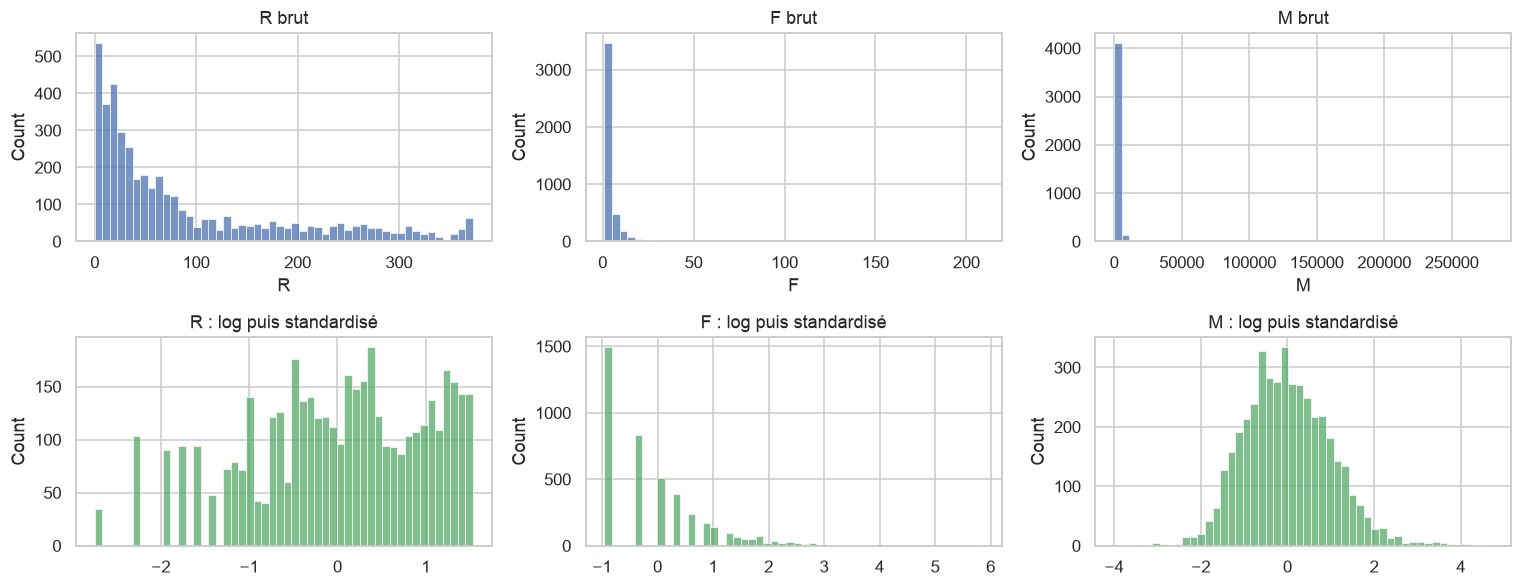

Corrélations (après log) :


,R,F,M
R,1.00,-0.57,-0.49
F,-0.57,1.00,0.81
M,-0.49,0.81,1.00


In [5]:
Z = StandardScaler().fit_transform(np.log1p(rfm))      # log(1 + x) puis z = (x - μ) / σ
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5))
for j, c in enumerate(["R", "F", "M"]):
    sns.histplot(rfm[c], bins=50, ax=axes[0, j], color="#4C72B0"); axes[0, j].set_title(f"{c} brut")
    sns.histplot(Z[:, j], bins=50, ax=axes[1, j], color="#55A868"); axes[1, j].set_title(f"{c} : log puis standardisé")
plt.tight_layout(); plt.savefig(FIG / "08_rfm_distributions.png", bbox_inches="tight"); plt.show()
print("Corrélations (après log) :")
np.log1p(rfm).corr().round(2)

**Lecture.** F et M ont des queues très longues (un client totalise 280 000 £ et 209 factures). Sans transformation, ces quelques clients domineraient les distances, comme l'âge non standardisé dans le jeu bancaire. On applique donc **log(1 + x)** puis la standardisation. F et M restent fortement corrélées (0,7 après log) : c'est attendu, plus on achète souvent, plus on dépense.

# Partie B — Clustering (Jours 2 et 3)
Avec 4 338 clients, la matrice des distances tient en mémoire : toutes les méthodes sont appliquées à **l'ensemble des clients**, sans échantillon.

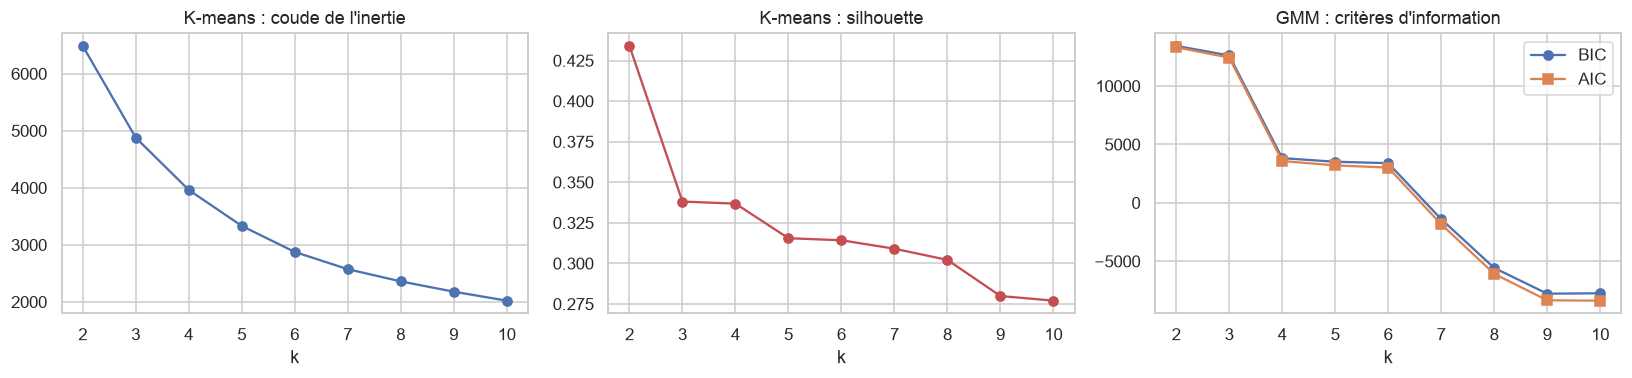

,k,inertie K-means,silhouette K-means,BIC GMM,AIC GMM
0,2,6488.007,0.434,13436.625,13315.497
1,3,4879.134,0.338,12611.880,12427.000
2,4,3962.703,0.337,3825.825,3577.193
3,5,3331.858,0.316,3516.278,3203.895
4,6,2875.401,0.314,3395.506,3019.371
5,7,2573.177,0.309,-1394.343,-1834.229
6,8,2359.569,0.302,-5572.372,-6076.010
7,9,2178.465,0.280,-7776.132,-8343.522
8,10,2021.274,0.277,-7743.312,-8374.454


In [6]:
D = pairwise_distances(Z)
rows, parts = [], {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=SEED).fit(Z)
    parts[f"kmeans_k{k}"] = km.labels_
    parts[f"gmm_k{k}"] = gmm.predict(Z)
    parts[f"ward_k{k}"] = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)
    rows.append({"k": k, "inertie K-means": km.inertia_, "silhouette K-means": silhouette_score(Z, km.labels_),
                 "BIC GMM": gmm.bic(Z), "AIC GMM": gmm.aic(Z)})
for k in range(2, 7):
    parts[f"kmedoids_k{k}"] = kmedoids(D, k)[0]
curves = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(curves["k"], curves["inertie K-means"], "o-"); axes[0].set_title("K-means : coude de l'inertie")
axes[1].plot(curves["k"], curves["silhouette K-means"], "o-", color="#C44E52"); axes[1].set_title("K-means : silhouette")
axes[2].plot(curves["k"], curves["BIC GMM"], "o-", label="BIC"); axes[2].plot(curves["k"], curves["AIC GMM"], "s-", label="AIC")
axes[2].set_title("GMM : critères d'information"); axes[2].legend()
for ax in axes: ax.set_xlabel("k"); ax.set_xticks(range(2, 11))
plt.tight_layout(); plt.savefig(FIG / "08_choix_k.png", bbox_inches="tight"); plt.show()
curves.round(3)

In [7]:
# DBSCAN : epsilon au coude du graphique des k-distances
MIN_SAMPLES = 8                                    # 2 × dimension + 2, règle usuelle
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z).kneighbors(Z)[0][:, -1])
EPS = float(kdist[knee_point(kdist)])
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Z)
parts["dbscan"] = db
print(f"ε = {EPS:.3f} ; {db.max() + 1} clusters ; bruit : {100 * (db == -1).mean():.1f} % ; tailles : {np.bincount(db[db >= 0])}")

ε = 0.398 ; 3 clusters ; bruit : 3.8 % ; tailles : [1881 1467  824]


**Lecture.** La silhouette de K-means est maximale à k = 2 (0,43), puis se stabilise autour de 0,34 pour k = 3 et 4 avant de baisser lentement. L'inertie n'a pas de cassure franche ; le BIC du GMM chute nettement entre 3 et 4 composantes. Comme pour le jeu bancaire, le choix final tiendra compte de la stabilité et du besoin métier.

# Partie C — Validation (Jour 4)
## C.1 Indices internes et indices externes
**Référence externe** : la segmentation RFM « classique ». Chaque client reçoit une note de 1 à 5 par quintile de R, F et M, puis une règle métier usuelle le range parmi cinq groupes (Champions, Fidèles, Nouveaux ou prometteurs, À risque, Perdus).

In [8]:
quint = lambda s, asc: pd.qcut(s.rank(method="first", ascending=asc), 5, labels=[1, 2, 3, 4, 5]).astype(int)
scores = pd.DataFrame({"r": quint(rfm["R"], False), "f": quint(rfm["F"], True), "m": quint(rfm["M"], True)}, index=rfm.index)
def classic_segment(s):
    if s.r >= 4 and s.f >= 4: return "Champions"
    if s.r >= 3 and s.f >= 3: return "Fidèles"
    if s.r >= 4:              return "Nouveaux ou prometteurs"
    if s.f >= 3:              return "À risque"
    return "Perdus"
ref_seg = scores.apply(classic_segment, axis=1)
print(ref_seg.value_counts().to_string())

NAMES = {"kmeans": "K-means", "kmedoids": "K-medoids", "gmm": "GMM", "ward": "CAH Ward", "dbscan": "DBSCAN"}
rows = []
for name, lab in parts.items():
    key, _, k = name.rpartition("_k")
    method = NAMES[key] if key else NAMES[name]
    m = lab >= 0
    if method != "DBSCAN" and int(k) > 6:
        continue
    h, c, v = homogeneity_completeness_v_measure(ref_seg[m], lab[m])
    rows.append({"méthode": method, "nb clusters": len(np.unique(lab[m])),
                 "plus petit cluster (%)": 100 * np.bincount(lab[m]).min() / len(lab),
                 "silhouette": silhouette_score(Z[m], lab[m]), "Davies-Bouldin": davies_bouldin_score(Z[m], lab[m]),
                 "Dunn": dunn_index(D[np.ix_(m, m)], lab[m]),
                 "ARI (réf. RFM)": adjusted_rand_score(ref_seg[m], lab[m]), "NMI (réf. RFM)": normalized_mutual_info_score(ref_seg[m], lab[m]),
                 "V-mesure (réf. RFM)": v})
indices = pd.DataFrame(rows)
indices.to_csv(TAB / "08_indices.csv", index=False)
indices.style.format(precision=3).format({"plus petit cluster (%)": "{:.1f}"}).hide(axis="index")

Perdus                     1427
Champions                  1121
Fidèles                     824
À risque                    658
Nouveaux ou prometteurs     308


méthode,nb clusters,plus petit cluster (%),silhouette,Davies-Bouldin,Dunn,ARI (réf. RFM),NMI (réf. RFM),V-mesure (réf. RFM)
K-means,2,38.1,0.434049,0.892035,0.002416,0.319990,0.366114,0.366114
GMM,2,34.4,0.284876,1.062946,0.058262,0.318540,0.452032,0.452032
CAH Ward,2,46.3,0.393288,0.946859,0.005598,0.353511,0.374520,0.374520
K-means,3,17.2,0.338098,1.048305,0.003535,0.364097,0.395820,0.395820
GMM,3,22.3,0.254168,1.243207,0.006675,0.418131,0.484281,0.484281
CAH Ward,3,13.4,0.320569,1.095399,0.007094,0.333517,0.405157,0.405157
K-means,4,16.1,0.336833,1.012974,0.000918,0.426748,0.449643,0.449643
GMM,4,19.2,0.175130,1.704715,0.008827,0.469797,0.504142,0.504142
CAH Ward,4,12.6,0.297396,1.002216,0.007094,0.340489,0.407865,0.407865
K-means,5,6.7,0.315517,0.995377,0.000834,0.410485,0.471538,0.471538


**Lecture.**
- **Indices internes** : K-means domine à chaque k (silhouette 0,43 à k = 2, puis 0,34 à k = 3 et 4). Ward et K-medoids suivent de près ; le GMM et DBSCAN sont nettement en retrait en silhouette. L'indice de Dunn est presque nul pour toutes les méthodes : les clients forment un **continuum** sans frontières nettes, comme dans le jeu bancaire.
- **Indices externes** : l'accord avec la segmentation RFM classique est modéré (ARI de 0,3 à 0,5). C'est normal : la règle par quintiles découpe l'espace par seuils fixes, alors que le clustering suit la densité réelle des clients. K-means à k = 4 a le meilleur accord des solutions K-means (0,43) ; le GMM s'en approche davantage (jusqu'à 0,47), mais avec des silhouettes faibles.

## C.2 Stabilité (bootstrap, 20 rééchantillons)

In [9]:
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(Z), len(Z)) for _ in range(20)]
stab = []
for k in range(2, 7):
    for name, fit in [("K-means", lambda X: KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)),
                      ("CAH Ward", lambda X: AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X))]:
        refp = parts[f"{'kmeans' if name == 'K-means' else 'ward'}_k{k}"]
        a = [adjusted_rand_score(refp[ib], fit(Z[ib])) for ib in boot_idx]
        stab.append({"k": k, "méthode": name, "ARI moyen": np.mean(a), "écart-type": np.std(a)})
stab = pd.DataFrame(stab)
stab.to_csv(TAB / "08_stabilite.csv", index=False)
stab.pivot(index="k", columns="méthode", values="ARI moyen").round(3)

méthode,CAH Ward,K-means
k,,
2,0.451,0.977
3,0.454,0.940
4,0.419,0.906
5,0.410,0.820
6,0.494,0.826


**Lecture.** K-means est **très stable** (0,98 à k = 2, 0,94 à k = 3, 0,91 à k = 4), alors que Ward est **instable** à tous les k (environ 0,45). C'est l'inverse du jeu bancaire, où Ward l'emportait. Avec trois variables continues et des groupes de forme ronde, K-means est dans son domaine. Les fusions de Ward, elles, dépendent fortement des quelques clients extrêmes présents ou non dans le rééchantillon. **Aucune méthode n'est la meilleure en général** : le choix doit être refait sur chaque jeu de données.

## C.3 Choix de la solution
Même démarche que pour le jeu bancaire. Le classement se fait sur les **indices internes** et la **stabilité** ; l'accord avec la segmentation RFM classique ne sert que de contrôle.

In [10]:
FINAL_K = 4
final = parts[f"kmeans_k{FINAL_K}"]
row = indices[(indices["méthode"] == "K-means") & (indices["nb clusters"] == FINAL_K)].iloc[0]
s_row = stab[(stab["méthode"] == "K-means") & (stab["k"] == FINAL_K)].iloc[0]
print(f"Solution retenue : K-means, k = {FINAL_K}")
print(f"  silhouette {row['silhouette']:.3f} | Davies-Bouldin {row['Davies-Bouldin']:.3f} | stabilité {s_row['ARI moyen']:.3f} "
      f"| ARI avec la segmentation RFM classique {row['ARI (réf. RFM)']:.3f}")

Solution retenue : K-means, k = 4
  silhouette 0.337 | Davies-Bouldin 1.013 | stabilité 0.906 | ARI avec la segmentation RFM classique 0.427


**Justification du choix : K-means, k = 4.**

| Critère | Constat |
|---|---|
| Indices internes | Silhouette de 0,34, égale à celle de k = 3 et seulement en dessous de k = 2 (0,43) ; Davies-Bouldin de 1,01, proche du minimum (0,995 à k = 5). |
| Stabilité | ARI bootstrap de 0,91, contre 0,42 pour Ward au même k. |
| Métier | k = 2 se contente d'opposer bons et mauvais clients ; k = 4 distingue les nouveaux clients des clients réguliers, qui n'appellent pas la même action. |
| Contrôle externe | Meilleur accord avec la segmentation RFM classique parmi les solutions K-means (ARI 0,43). Le GMM fait un peu mieux (0,47), mais avec une silhouette deux fois plus faible. |

# Partie D — Interprétation (Jour 5)

In [11]:
prof = rfm.assign(segment=final).groupby("segment").agg(
    clients=("R", "size"), R_médiane=("R", "median"), F_médiane=("F", "median"), M_médiane=("M", "median"),
    CA_total=("M", "sum"))
prof["% des clients"] = 100 * prof["clients"] / prof["clients"].sum()
prof["% du chiffre d'affaires"] = 100 * prof["CA_total"] / prof["CA_total"].sum()
# Nommage automatique d'après les profils
order = prof.sort_values("M_médiane", ascending=False).index
names = {}
for s in prof.index:
    p = prof.loc[s]
    if s == order[0]:                                   names[s] = "Champions"
    elif p["R_médiane"] > 100:                          names[s] = "Perdus"
    elif p["F_médiane"] <= 2 and p["R_médiane"] < 30:   names[s] = "Nouveaux clients"
    else:                                               names[s] = "Réguliers"
prof.insert(0, "nom", prof.index.map(names))
prof = prof.sort_values("% du chiffre d'affaires", ascending=False)
prof.drop(columns="CA_total").round(1).to_csv(TAB / "08_profils_segments.csv")
prof.drop(columns="CA_total").round(1)

,nom,clients,R_médiane,F_médiane,M_médiane,% des clients,% du chiffre d'affaires
segment,,,,,,,
0,Champions,699,8.0,10.0,3750.4,16.1,64.5
3,Réguliers,1178,53.5,4.0,1351.8,27.2,24.1
1,Perdus,1635,173.0,1.0,296.6,37.7,6.3
2,Nouveaux clients,826,16.0,2.0,480.1,19.0,5.2


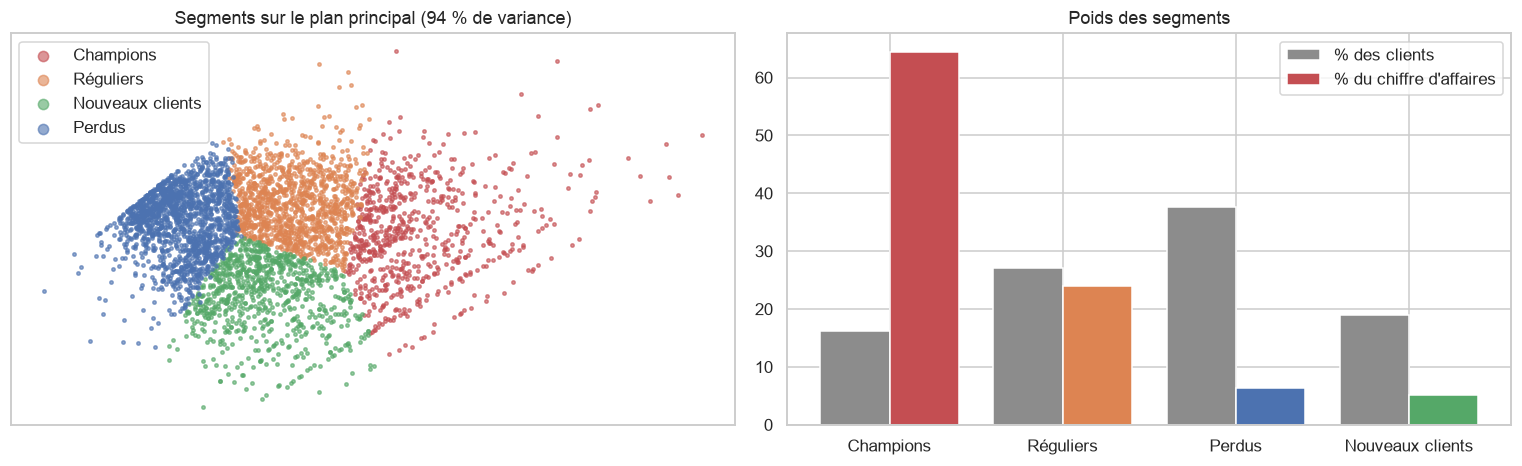

segment RFM classique,Champions,Fidèles,Nouveaux ou prometteurs,Perdus,À risque
segment K-means,,,,,
Champions,661,33,0,0,5
Nouveaux clients,175,317,288,46,0
Perdus,0,49,11,1285,290
Réguliers,285,425,9,96,363


In [12]:
pca = PCA(n_components=2, random_state=SEED).fit(Z)
P2 = pca.transform(Z)
pal = {"Champions": "#C44E52", "Réguliers": "#DD8452", "Nouveaux clients": "#55A868", "Perdus": "#4C72B0"}
seg_name = pd.Series(final).map(names).values
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for nm, c in pal.items():
    m = seg_name == nm
    axes[0].scatter(P2[m, 0], P2[m, 1], s=5, c=c, label=nm, alpha=.6)
axes[0].set_title(f"Segments sur le plan principal ({100 * pca.explained_variance_ratio_.sum():.0f} % de variance)")
axes[0].legend(markerscale=3); axes[0].set_xticks([]); axes[0].set_yticks([])
x = np.arange(len(prof))
axes[1].bar(x - 0.2, prof["% des clients"], 0.4, label="% des clients", color="#8C8C8C")
axes[1].bar(x + 0.2, prof["% du chiffre d'affaires"], 0.4, label="% du chiffre d'affaires", color=[pal[n] for n in prof["nom"]])
axes[1].set_xticks(x); axes[1].set_xticklabels(prof["nom"]); axes[1].legend(); axes[1].set_title("Poids des segments")
plt.tight_layout(); plt.savefig(FIG / "08_segments.png", bbox_inches="tight"); plt.show()
pd.crosstab(pd.Series(seg_name, name="segment K-means"), pd.Series(ref_seg.values, name="segment RFM classique"))

**Profils et recommandations.**

| Segment | Profil | Recommandation |
|---|---|---|
| **Champions** (16 % des clients, **65 % du CA**) | Achat très récent (8 jours), 10 factures, 3 750 £ en médiane | Programme de fidélité, accès en avant-première, interlocuteur dédié : c'est le segment à ne pas perdre. |
| **Réguliers** (27 %, 24 % du CA) | Dernier achat il y a 2 mois, 4 factures | Relances ciblées et ventes croisées pour les faire monter vers les Champions. |
| **Nouveaux clients** (19 %, 5 % du CA) | Achat récent (16 jours) mais 1 à 2 factures | Parcours d'accueil, offre sur la deuxième commande : transformer l'essai. |
| **Perdus** (38 %, 6 % du CA) | Aucun achat depuis près de 6 mois, une seule facture | Campagne de reconquête peu coûteuse (courriel automatisé) ; ne pas y consacrer de budget important. |

Un client sur six génère deux tiers du chiffre d'affaires. La même logique que pour la banque s'applique : concentrer l'effort commercial là où la réponse est la plus forte.

## Bilan de la reproduction
1. La démarche du projet (préparation, choix des distances, comparaison de 5 méthodes, validation interne, externe et stabilité, interprétation) **s'applique telle quelle** à un second jeu de données.
2. Les mêmes leçons se retrouvent : il faut transformer les variables asymétriques, un indice ne se lit pas seul, et la structure est un continuum (Dunn presque nul).
3. Une différence instructive : la **méthode gagnante change**. Ward est la plus stable sur les données bancaires mixtes ; K-means l'est sur les trois variables RFM continues.
4. Solution retenue : **K-means à 4 segments** (silhouette 0,34 ; stabilité 0,91). Les **Champions** (16 % des clients) font 65 % du chiffre d'affaires.